In [61]:
pip install pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [62]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [63]:
dg1 = pd.read_csv('data/data_group_1.csv')
dg2 = pd.read_csv('data/data_group_2.csv')
dg3 = pd.read_csv('data/data_group_3.csv')

In [64]:
frames = [dg1, dg2, dg3]

df = pd.concat(frames)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11160 entries, 0 to 3719
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   timestamp       11160 non-null  object 
 1   turbine_id      11160 non-null  int64  
 2   wind_speed      11160 non-null  float64
 3   wind_direction  11160 non-null  int64  
 4   power_output    11160 non-null  float64
dtypes: float64(2), int64(2), object(1)
memory usage: 523.1+ KB


In [65]:
df.describe()

,turbine_id,wind_speed,wind_direction,power_output
count,11160.000000,11160.000000,11160.000000,11160.000000
mean,8.000000,12.002724,179.903943,3.001927
std,4.320687,1.735366,103.353513,0.869831
min,1.000000,9.000000,0.000000,1.500000
25%,4.000000,10.500000,91.000000,2.275000
50%,8.000000,12.000000,180.000000,3.000000
75%,12.000000,13.500000,269.000000,3.800000
max,15.000000,15.000000,359.000000,4.500000


I've loaded the data in and checked the data types and size of the overall joint dataset.

In [66]:
df.isna().any()

timestamp         False
turbine_id        False
wind_speed        False
wind_direction    False
power_output      False
dtype: bool

In [67]:
df[df.duplicated()]

,timestamp,turbine_id,wind_speed,wind_direction,power_output


I've checked for any null values in the dataset and duplicate values, but can't find any. I've also tried to check manually but can't see any null values (obviously duplicates are more difficult).

In [68]:
df = df.sort_values(by=["timestamp","turbine_id"])
df.head(15)

,timestamp,turbine_id,wind_speed,wind_direction,power_output
0,2022-03-01 00:00:00,1,11.8,169,2.7
1,2022-03-01 00:00:00,2,11.6,24,2.2
2,2022-03-01 00:00:00,3,13.8,335,2.3
3,2022-03-01 00:00:00,4,12.8,238,1.9
4,2022-03-01 00:00:00,5,11.4,103,3.5
0,2022-03-01 00:00:00,6,15.0,112,4.2
1,2022-03-01 00:00:00,7,10.8,308,3.9
2,2022-03-01 00:00:00,8,12.6,201,2.9
3,2022-03-01 00:00:00,9,9.5,8,3.2
4,2022-03-01 00:00:00,10,10.7,44,3.4


As the data sets are joined together but not sorted together, I've sorted the data on the timestamp and turbine_id values. This shows all 15 turbines next to each other.

<Axes: xlabel='turbine_id', ylabel='wind_speed'>

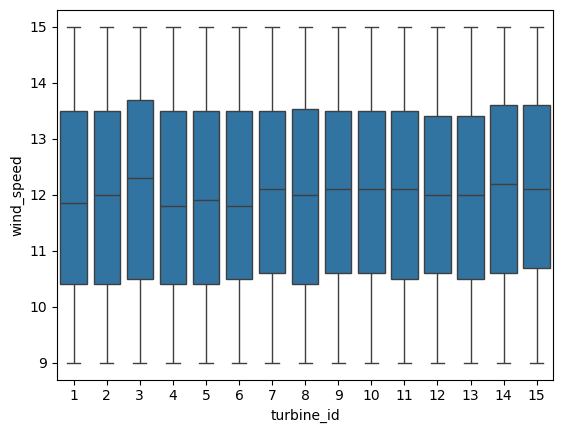

In [69]:
sns.boxplot(data=df, x="turbine_id", y="wind_speed")

<Axes: xlabel='turbine_id', ylabel='wind_direction'>

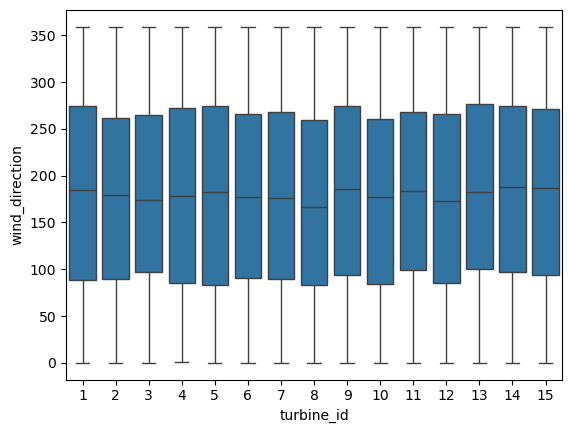

In [70]:
sns.boxplot(data=df, x="turbine_id", y="wind_direction")

<Axes: xlabel='turbine_id', ylabel='power_output'>

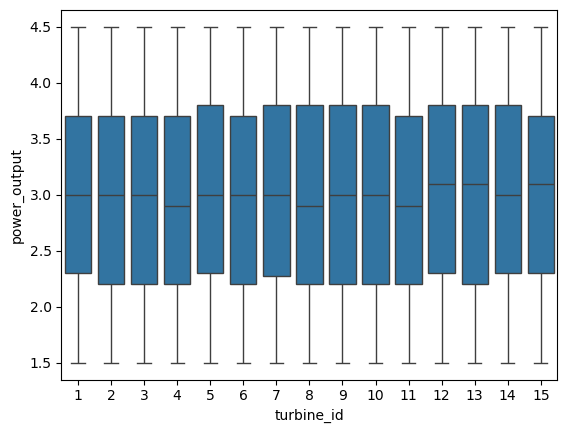

In [71]:
sns.boxplot(data=df, x="turbine_id", y="power_output")

I've checked here for any outlier values in the wind_speed, wind_direction and power_output columns but can't see any. The values for wind_direction are between 0 and 360, with the assumption that this is the angle of the wind.

In [72]:
df['timestamp'] = df['timestamp'].apply(pd.to_datetime)
df_avg = df.groupby([df['timestamp'].dt.date, 'turbine_id']).agg({'power_output':[np.min,np.max,np.mean,np.median,np.std]})
df_avg.head()

power_output                                
                              amin amax      mean median       std
timestamp  turbine_id                                             
2022-03-01 1                   1.6  4.4  2.975000   2.75  0.920893
           2                   1.6  4.4  2.983333   2.95  0.980535
           3                   1.6  4.5  2.766667   2.45  0.885470
           4                   1.5  4.4  3.020833   3.15  0.845437
           5                   1.7  4.5  3.079167   2.95  0.765551

Here I'm compiling the daily values, the min-max values and averages, along with the standard deviation of each value. None of the turbines have a standard deviation above 2, so it's not necessary to flag any.

In [73]:
df_avg.to_csv("daily_avg.csv", index=True)
df.to_csv("clean.csv", index=True)

Here I'm outputting the cleaned data and the daily averages data to seperate files.